# Tome C5, Chapter 2: Krylov Spaces and Random Sketches (Python companion)

Exercises first, solutions at the end. We race conjugate gradients against steepest descent on a grid with ten thousand unknowns, let the method find outliers on its own, watch Lanczos beat the power method by a factor of two hundred and then produce ghosts, cut two half-moons apart with an eigenvector, and shrink large problems with random matrices: subspace embeddings, sketched least squares and the randomised SVD.

*Before each solution, predict what the output will look like.*

In [1]:
import math, time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spl
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, linewidth=110)

## Exercises

**P2.1 (★) Conjugate gradients on a grid.** Build the discrete Laplacian of a $100\times100$ grid, compute its condition number exactly, and run conjugate gradients (Theorem 2.4) and steepest descent on $Ax=b$ for a random $b$. How many steps does CG need to divide the energy error by $10^6$? Compare with the bound of Theorem 2.5(2) and with Exercise 2.1. Then add five huge eigenvalues and check part (3) of the theorem.

**P2.2 (★★) Lanczos against the power method.** Take a diagonal matrix of size $2000$ with eigenvalues spread over $[0,1]$ and a top eigenvalue $1+10^{-4}$, so that the relative gap of Theorem 2.7 is $\gamma\approx10^{-4}$. Count the steps each method needs to divide the error $\lambda_1-\theta$ by $e^{10}$.

**P2.3 (★) Ghosts.** Run the Lanczos recurrence of Proposition 2.6 without reorthogonalisation on $\operatorname{diag}(1,\dots,100)$, $b=\mathbf 1$, for $200$ steps (Exercise 2.12). How many Ritz values lie within $10^{-6}$ of $100$? Of $1$? Repeat with full reorthogonalisation.

**P2.4 (★★) Spectral clustering.** Generate two noisy interleaved half-moons of $300$ points, build the Gaussian $10$-nearest-neighbour graph, and compute $\lambda_2$ of $Lx=\lambda Dx$ and the best sweep cut (Theorem 2.8, Figure 2.2). Check the random-walk identity of Exercise 2.10 on the cut you found, and the path formulas of Exercise 2.11.

**P2.5 (★★) Subspace embeddings.** For $d=50$, sample $k\times d$ Gaussian matrices with $N(0,\frac1k)$ entries and measure the distortion $\max_i|\sigma_i^2-1|$ for $k=200,\dots,12800$. Compare with the guarantee of Theorem 2.13 and with Gordon's $2\sqrt{d/k}+d/k$, and check $\mathbb E\|G\|^2\ge1+\frac{d-1}k$ (Exercise 2.7). Count the points of the best $\varepsilon$-net of the circle (Exercise 2.6).

**P2.6 (★★) Sketch and solve.** Solve a least squares problem with $n=20000$ rows and $d=50$ columns exactly and through a Gaussian sketch and a CountSketch with $k=1000$ rows. Compare the residuals with Theorem 2.14, and illustrate Exercise 2.8.

**P2.7 (★★) Randomised SVD.** Draw a synthetic $512\times512$ picture, compute the relative error of the randomised range finder with $k=r+10$ columns, with and without one power iteration, against the best rank-$r$ error (Theorem 2.15, Figure 2.3). Check Exercise 2.9 on a matrix of rank $20$, and compare the running time with a full SVD on a $2000\times2000$ matrix of rank $50$.

## Solutions

### P2.1

n = 10000, nonzeros = 49600, kappa = 4133.6, sqrt(kappa) = 64.3
600 CG steps in 0.07 s
CG steps to 1e-6: 264   bound sqrt(kappa)/2 ln(2e6) = 467
steepest descent after 600 steps: 0.216; predicted ((kappa-1)/(kappa+1))^600 = 0.748
Exercise cgcount, kappa = 1e4: 726 CG steps against 69078


five outliers up to 1e6 (kappa about 5e8): CG steps to 1e-6: 688   with reorthogonalisation: 278


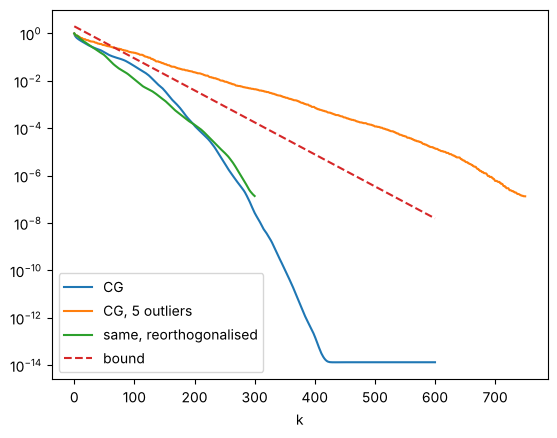

In [2]:
def grid_laplacian(m):
    T = sp.diags([-np.ones(m - 1), 2 * np.ones(m), -np.ones(m - 1)], [-1, 0, 1])
    I = sp.identity(m)
    return (sp.kron(I, T) + sp.kron(T, I)).tocsr()

def cg(A, b, xs, steps, reorth=False):
    en = lambda e: math.sqrt(e @ (A @ e)); e0 = en(xs)
    x = np.zeros_like(b); r = b.copy(); p = r.copy(); rr = r @ r; hist = [1.0]
    if reorth: Rk = np.zeros((len(b), steps + 1)); Rk[:, 0] = r / math.sqrt(rr)
    for k in range(steps):
        Ap = A @ p; al = rr / (p @ Ap); x += al * p; r -= al * Ap
        if reorth:                             # keep the residuals orthogonal, as in exact arithmetic
            r -= Rk[:, :k + 1] @ (Rk[:, :k + 1].T @ r)
        rn = r @ r; p = r + (rn / rr) * p; rr = rn
        if reorth: Rk[:, k + 1] = r / math.sqrt(rn)
        hist.append(en(x - xs) / e0)
    return np.array(hist)

m = 100; A = grid_laplacian(m); n = m * m
lmin, lmax = 4 - 4 * math.cos(math.pi / (m + 1)), 4 + 4 * math.cos(math.pi / (m + 1))
kappa = lmax / lmin; rho = (math.sqrt(kappa) - 1) / (math.sqrt(kappa) + 1)
print(f"n = {n}, nonzeros = {A.nnz}, kappa = {kappa:.1f}, sqrt(kappa) = {math.sqrt(kappa):.1f}")
rng = np.random.default_rng(0)
b = rng.standard_normal(n); xs = spl.spsolve(A.tocsc(), b)
t = time.time(); h = cg(A, b, xs, 600); print(f"600 CG steps in {time.time()-t:.2f} s")
first_below = lambda h, tol: int(np.nonzero(h < tol)[0][0]) if np.any(h < tol) else None
print("CG steps to 1e-6:", first_below(h, 1e-6), "  bound sqrt(kappa)/2 ln(2e6) =", math.ceil(math.log(2e6) / -math.log(rho)))
en = lambda e: math.sqrt(e @ (A @ e)); x = np.zeros(n); sd = []
for k in range(600):
    r = b - A @ x; x += (r @ r) / (r @ (A @ r)) * r
print(f"steepest descent after 600 steps: {en(x - xs) / en(xs):.3f}; predicted ((kappa-1)/(kappa+1))^600 = {((kappa-1)/(kappa+1))**600:.3f}")
print("Exercise cgcount, kappa = 1e4:", math.ceil(math.log(2e6) / math.log(101 / 99)), "CG steps against", math.ceil(math.log(1e6) / math.log(10001 / 9999)))
# five outliers: A + V diag(1e3..) V^T on random orthonormal V
V, _ = np.linalg.qr(rng.standard_normal((n, 5))); big = np.array([1e2, 1e3, 1e4, 1e5, 1e6])
class Aout:  # A + V diag(big) V^T, applied without forming it
    def __matmul__(self, v): return A @ v + V @ (big * (V.T @ v))
lu = spl.splu(A.tocsc())                     # exact solution by the Woodbury formula
AiV = lu.solve(V); Aib = lu.solve(b)
xo = Aib - AiV @ np.linalg.solve(np.diag(1 / big) + V.T @ AiV, V.T @ Aib)
ho = cg(Aout(), b, xo, 750); hr = cg(Aout(), b, xo, 300, reorth=True)
print("five outliers up to 1e6 (kappa about 5e8): CG steps to 1e-6:", first_below(ho, 1e-6),
      "  with reorthogonalisation:", first_below(hr, 1e-6))
plt.semilogy(h, label="CG"); plt.semilogy(ho, label="CG, 5 outliers"); plt.semilogy(hr, label="same, reorthogonalised"); plt.semilogy(2 * rho ** np.arange(601), "--", label="bound")
plt.legend(); plt.xlabel("k"); plt.show()

The grid has $\kappa\approx4134$; the bound of Theorem 2.5(2) asks for $467$ steps and the method needs $264$, because the error of a random right-hand side is not concentrated on the worst eigenvectors and the optimal polynomial exploits the distribution of the spectrum, not only its ends. Steepest descent, after $600$ steps, has not even gained one digit. Adding a positive matrix of rank five, with eigenvalues up to $10^6$, leaves all but five eigenvalues inside $[\mu,L]$ (by interlacing) and creates five outliers; the condition number jumps to about $5\times10^8$, which would multiply the bound (2) by more than three hundred. In exact arithmetic, which we imitate by reorthogonalising the residuals, CG needs only about fifteen extra steps, as part (3) predicts: the optimal polynomial spends a root on each outlier. Plain floating point CG needs far more: this is the delay explained by Greenbaum (1989), mentioned in the remark after Theorem 2.5. Huge isolated eigenvalues are the one situation where rounding visibly hurts conjugate gradients.

### P2.2

In [3]:
rng = np.random.default_rng(2)
N = 2000
lam = np.r_[1 + 1e-4, np.sort(rng.uniform(0, 1, N - 1))[::-1]]
lam[1] = 1.0                                   # lambda_2 = 1, lambda_n near 0
gamma = (lam[0] - lam[1]) / (lam[1] - lam.min())
b = rng.standard_normal(N); b /= np.linalg.norm(b)
err0 = lam[0] - b @ (lam * b)                  # error of the starting Rayleigh quotient
target = err0 * math.exp(-10)
print(f"gamma = {gamma:.2e}, initial error = {err0:.3e}")
x = b.copy(); k = 0
while True:                                    # power method on a diagonal matrix
    x = lam * x; x /= np.linalg.norm(x); k += 1
    if lam[0] - x @ (lam * x) < target: break
print("power method steps to divide the error by e^10 from the start:", k)
errs = []
for j in range(100000):                        # continue, and measure the asymptotic rate
    x = lam * x; x /= np.linalg.norm(x)
    if j % 1000 == 0: errs.append(lam[0] - x @ (lam * x))
errs = np.log(np.array(errs)); slope = (errs[0] - errs[-1]) / (1000 * (len(errs) - 1))
print(f"power method, later on: {10 / slope:.0f} steps per factor e^10")
Q = np.zeros((N, 401)); Q[:, 0] = b; al = []; be = []
for j in range(400):                           # Lanczos with full reorthogonalisation
    w = lam * Q[:, j]; a = Q[:, j] @ w; al.append(a)
    w -= Q[:, :j + 1] @ (Q[:, :j + 1].T @ w); w -= Q[:, :j + 1] @ (Q[:, :j + 1].T @ w)
    bb = np.linalg.norm(w); be.append(bb); Q[:, j + 1] = w / bb
    T = np.diag(al) + np.diag(be[:-1], 1) + np.diag(be[:-1], -1)
    if lam[0] - np.linalg.eigvalsh(T)[-1] < target: break
print("Lanczos steps:", j + 1, "   predictions 5/gamma =", round(5 / gamma), " and 2.5/sqrt(gamma) =", round(2.5 / math.sqrt(gamma)))

gamma = 1.00e-04, initial error = 4.989e-01
power method steps to divide the error by e^10 from the start: 4138


power method, later on: 48836 steps per factor e^10
Lanczos steps: 108    predictions 5/gamma = 49937  and 2.5/sqrt(gamma) = 250


From the start, the power method gains the first factor $e^{10}$ fairly quickly, because most components of $b$ live on small eigenvalues and die fast. Then the gap takes over: each further factor $e^{10}$ costs about $49\,000$ steps, the $5/\gamma=50\,000$ predicted in the text. Lanczos needs about $110$ steps in all, better than its bound $2.5/\sqrt\gamma=250$. The square root of the gap is the whole story, exactly as for conjugate gradients, and for the same reason: Chebyshev polynomials.

### P2.3

In [4]:
def lanczos(a, b, steps, reorth):
    n = len(a); Q = np.zeros((n, steps + 1)); Q[:, 0] = b / np.linalg.norm(b); al, be = [], []
    for j in range(steps):
        w = a * Q[:, j]
        if j > 0: w -= be[-1] * Q[:, j - 1]
        al.append(Q[:, j] @ w); w -= al[-1] * Q[:, j]
        if reorth: w -= Q[:, :j + 1] @ (Q[:, :j + 1].T @ w)
        bb = np.linalg.norm(w)
        if bb < 1e-12: break
        be.append(bb); Q[:, j + 1] = w / bb
    k = len(al)
    return np.linalg.eigvalsh(np.diag(al) + np.diag(be[:k - 1], 1) + np.diag(be[:k - 1], -1)), k
a = np.arange(1.0, 101.0)
for reorth in (False, True):
    th, k = lanczos(a, np.ones(100), 200, reorth)
    print(f"reorth={reorth}: {k} steps, Ritz values near 100: {np.sum(abs(th - 100) < 1e-6)}, near 1: {np.sum(abs(th - 1) < 1e-6)},"
          f" distinct eigenvalues found within 1e-6: {sum(np.min(abs(th - l)) < 1e-6 for l in a)}")

reorth=False: 200 steps, Ritz values near 100: 4, near 1: 4, distinct eigenvalues found within 1e-6: 100
reorth=True: 100 steps, Ritz values near 100: 1, near 1: 1, distinct eigenvalues found within 1e-6: 100


Without reorthogonalisation, after $200$ steps the extreme eigenvalues $1$ and $100$ appear several times: ghosts, born when rounding reintroduces the converged eigenvectors into the Krylov vectors. With full reorthogonalisation the recurrence breaks down at step $100$ (Exercise 2.2), $T_{100}$ has exactly the eigenvalues $1,\dots,100$, and nothing is repeated.

### P2.4

lambda_2 = 1.046e-04, sweep Ncut = 1.282e-04, ratio = 1.225, points correctly separated: 100.0%
a straight cut, x < 0.5: 0.6966666666666667
P(leave S) + P(enter S) = 1.2815e-04  Ncut = 1.2815e-04


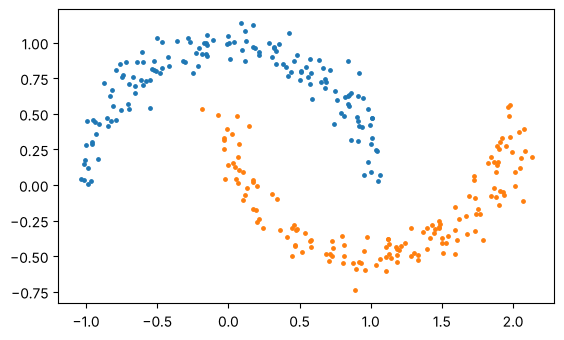

path n=50: lambda_2 = 0.002055, formula 1-cos(pi/(n-1)) = 0.002055; best Ncut = 0.04082 = 2/(n-1) = 0.04082


In [5]:
def moons(N, noise, rng):
    h = N // 2; t1 = rng.uniform(0, np.pi, h); t2 = rng.uniform(0, np.pi, N - h)
    X = np.vstack([np.c_[np.cos(t1), np.sin(t1)], np.c_[1 - np.cos(t2), 0.5 - np.sin(t2)]])
    return X + noise * rng.standard_normal(X.shape), np.r_[np.zeros(h), np.ones(N - h)]
rng = np.random.default_rng(3)
X, lab = moons(300, 0.08, rng); N = len(X)
D2 = ((X[:, None, :] - X[None, :, :]) ** 2).sum(-1)
nn = np.argsort(D2, axis=1)[:, 1:11]
s = math.sqrt(np.median(D2[np.arange(N)[:, None], nn]))
W = np.zeros((N, N))
for i in range(N): W[i, nn[i]] = np.exp(-D2[i, nn[i]] / (2 * s * s))
W = np.maximum(W, W.T); d = W.sum(1); L = np.diag(d) - W; Dm = 1 / np.sqrt(d)
ev, V = np.linalg.eigh(Dm[:, None] * L * Dm[None, :]); lam2 = ev[1]; f = Dm * V[:, 1]
order = np.argsort(f); vol = d.sum(); best = (np.inf, 0)
for j in range(1, N):
    S = np.zeros(N, bool); S[order[:j]] = True
    cut = W[S][:, ~S].sum(); vs = d[S].sum(); nc = cut * (1 / vs + 1 / (vol - vs))
    if nc < best[0]: best = (nc, j)
S = np.zeros(N, bool); S[order[:best[1]]] = True
acc = max(np.mean(S == (lab == 1)), np.mean(S == (lab == 0)))
print(f"lambda_2 = {lam2:.3e}, sweep Ncut = {best[0]:.3e}, ratio = {best[0]/lam2:.3f}, points correctly separated: {acc:.1%}")
print("a straight cut, x < 0.5:", max(np.mean((X[:, 0] < 0.5) == (lab == 0)), np.mean((X[:, 0] < 0.5) == (lab == 1))))
P = W / d[:, None]; pi = d / vol           # random walk check of Exercise ncutwalk
pSout = (pi[S][:, None] * P[S][:, ~S]).sum() / pi[S].sum(); pSin = (pi[~S][:, None] * P[~S][:, S]).sum() / pi[~S].sum()
print("P(leave S) + P(enter S) =", f"{pSout + pSin:.4e}", " Ncut =", f"{best[0]:.4e}")
plt.scatter(*X[S].T, s=6); plt.scatter(*X[~S].T, s=6); plt.gca().set_aspect("equal"); plt.show()
# Exercise ncutpath: the path with n vertices
n = 50; Wp = np.diag(np.ones(n - 1), 1); Wp += Wp.T; dp = Wp.sum(1)
lp = np.linalg.eigvalsh(np.diag(dp ** -0.5) @ (np.diag(dp) - Wp) @ np.diag(dp ** -0.5))[1]
cuts = [1 / (2 * s_ - 1) + 1 / (2 * n - 2 * s_ - 1) for s_ in range(1, n)]
print(f"path n={n}: lambda_2 = {lp:.6f}, formula 1-cos(pi/(n-1)) = {1 - math.cos(math.pi / (n - 1)):.6f}; best Ncut = {min(cuts):.5f} = 2/(n-1) = {2/(n-1):.5f}")

The eigenvector separates the two moons without a single error, where the best straight cut misclassifies a noticeable fraction; the sweep cut's normalised cut is only about $1.23$ times the lower bound $\lambda_2$, so on this graph the relaxation of Shi and Malik loses almost nothing. The random-walk identity of Exercise 2.10 holds to rounding. On the path, by contrast, $\lambda_2\approx\pi^2/(2n^2)$ while the best cut is $2/(n-1)$: a factor of order $n$, the worst case allowed by Cheeger's inequality.

### P2.5

In [6]:
rng = np.random.default_rng(4)
d = 50
print("   k   distortion  Gordon 2sqrt(d/k)+d/k   E||G||^2-1   (d-1)/k")
for k in [200, 400, 800, 1600, 3200, 6400, 12800]:
    dist, top = [], []
    for t in range(5):
        sv = np.linalg.svd(rng.standard_normal((k, d)) / math.sqrt(k), compute_uv=False)
        dist.append(max(sv[0] ** 2 - 1, 1 - sv[-1] ** 2)); top.append(sv[0] ** 2 - 1)
    print(f"{k:5d}   {np.mean(dist):.3f}       {2*math.sqrt(d/k)+d/k:.3f}                {np.mean(top):.3f}       {(d-1)/k:.4f}")
eps, delta = 0.5, 0.1
print("Theorem embedding guarantees distortion 0.5 from k =", math.ceil(24 * (d * math.log(9) + math.log(2 / delta)) / eps ** 2))
for eps_ in (0.2, 0.1):
    k = round(4 * d / eps_ ** 2); sv = np.linalg.svd(rng.standard_normal((k, d)) / math.sqrt(k), compute_uv=False)
    print(f"k = 4d/eps^2 = {k} for eps = {eps_}: measured distortion {max(sv[0]**2 - 1, 1 - sv[-1]**2):.3f}")
for e in (0.5, 0.1, 0.01):                     # nets of the circle, Exercise netlower
    N = math.ceil(math.pi / (2 * math.asin(e / 2)))
    ang = 2 * np.pi * np.arange(N) / N; pts = np.c_[np.cos(ang), np.sin(ang)]
    test = np.linspace(0, 2 * np.pi, 20001); T = np.c_[np.cos(test), np.sin(test)]
    cover = np.sqrt(((T[:, None, :] - pts[None, :, :]) ** 2).sum(-1)).min(1).max()
    print(f"eps = {e}: minimal net size {N}, covering radius of {N} equal points = {cover:.5f}; with {N-1} points: "
          f"{2*math.sin(math.pi/(2*(N-1))):.5f}")

   k   distortion  Gordon 2sqrt(d/k)+d/k   E||G||^2-1   (d-1)/k


  200   1.115       1.250                1.115       0.2450
  400   0.753       0.832                0.753       0.1225
  800   0.537       0.562                0.537       0.0612
 1600   0.361       0.385                0.361       0.0306


 3200   0.260       0.266                0.260       0.0153
 6400   0.183       0.185                0.183       0.0077


12800   0.123       0.129                0.120       0.0038
Theorem embedding guarantees distortion 0.5 from k = 10835
k = 4d/eps^2 = 5000 for eps = 0.2: measured distortion 0.199
k = 4d/eps^2 = 20000 for eps = 0.1: measured distortion 0.105


eps = 0.5: minimal net size 7, covering radius of 7 equal points = 0.44504; with 6 points: 0.51764
eps = 0.1: minimal net size 32, covering radius of 32 equal points = 0.09798; with 31 points: 0.10130


eps = 0.01: minimal net size 315, covering radius of 315 equal points = 0.00997; with 314 points: 0.01001


The measured distortion follows Gordon's prediction $2\sqrt{d/k}+d/k$ closely, and the lower bound $(d-1)/k$ of Exercise 2.7 is far below it, as a crude bound should be. Theorem 2.13 asks for about $11\,000$ rows to guarantee distortion $\frac12$ in dimension $50$, while $800$ already give about $0.54$ and $1600$ about $0.36$: the union bound over nets is honest but generous. With $k=4d/\varepsilon^2$ rows the distortion is close to $\varepsilon$, as stated in the text. For the circle, the equally spaced net of the minimal size has covering radius at most $\varepsilon$, and one point fewer does not suffice.

### P2.6

In [7]:
rng = np.random.default_rng(6)
n, d, k = 20000, 50, 1000
A = rng.standard_normal((n, d)) * np.logspace(0, -3, d)          # condition number about 1e3
xtrue = rng.standard_normal(d); b = A @ xtrue + 0.1 * rng.standard_normal(n)
xs = np.linalg.lstsq(A, b, rcond=None)[0]; r0 = np.linalg.norm(A @ xs - b)
t = time.time(); G = rng.standard_normal((k, n)) / math.sqrt(k)
xg = np.linalg.lstsq(G @ A, G @ b, rcond=None)[0]; tg = time.time() - t
t = time.time(); h = rng.integers(0, k, n); sg = rng.choice([-1.0, 1.0], n)
S = sp.csr_matrix((sg, (h, np.arange(n))), shape=(k, n))
xc = np.linalg.lstsq(S @ A, S @ b, rcond=None)[0]; tc = time.time() - t
for name, xt, tt in [("Gaussian", xg, tg), ("CountSketch", xc, tc)]:
    ratio = np.linalg.norm(A @ xt - b) / r0
    print(f"{name:11s}: residual ratio {ratio:.4f}, time {tt:.3f} s, ||A(x~ - x*)||^2/||Ax*-b||^2 = "
          f"{np.linalg.norm(A @ (xt - xs))**2 / r0**2:.4f}, ||x~ - x*|| = {np.linalg.norm(xt - xs):.3f}")
sv = np.linalg.svd(G @ np.linalg.qr(np.c_[A, b])[0], compute_uv=False)
eps = max(sv[0] ** 2 - 1, 1 - sv[-1] ** 2)
print(f"measured distortion of the Gaussian sketch on span(A, b): {eps:.3f}; bound sqrt((1+e)/(1-e)) = {math.sqrt((1+eps)/(1-eps)):.3f}")

Gaussian   : residual ratio 1.0320, time 0.854 s, ||A(x~ - x*)||^2/||Ax*-b||^2 = 0.0650, ||x~ - x*|| = 7.435
CountSketch: residual ratio 1.0297, time 0.005 s, ||A(x~ - x*)||^2/||Ax*-b||^2 = 0.0603, ||x~ - x*|| = 6.004
measured distortion of the Gaussian sketch on span(A, b): 0.503; bound sqrt((1+e)/(1-e)) = 1.738


Both sketches give a residual within a few percent of the optimum, well inside the guarantee $\sqrt{(1+\varepsilon)/(1-\varepsilon)}$ computed from the measured distortion; the CountSketch is much faster to apply, since it touches each row of $A$ once. The solution itself moves much more than the residual ratio suggests, because $A$ has condition number $10^3$: this is Exercise 2.8. The residual is good, the coefficients along the small singular directions are not.

### P2.7

  r    q=0     q=1    best rank r
 10  0.0830  0.0521   0.0763
 20  0.0661  0.0410   0.0497
 50  0.0389  0.0251   0.0269


100  0.0185  0.0112   0.0120


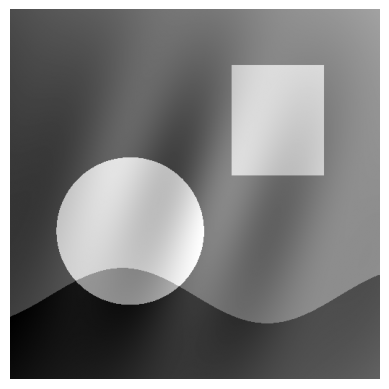

rank 20, k = 20: relative error 8.540772033374893e-14


2000x2000 of rank 50: full SVD 0.99 s, randomised 0.025 s


In [8]:
def picture(N=512):
    u = np.linspace(-1, 1, N); Xg, Yg = np.meshgrid(u, u)
    img = 0.3 + 0.2 * Xg + 0.1 * Yg ** 2
    img += 0.6 * ((Xg + 0.35) ** 2 + (Yg - 0.2) ** 2 < 0.16)
    img += 0.4 * ((np.abs(Xg - 0.45) < 0.25) & (np.abs(Yg + 0.4) < 0.3))
    img -= 0.3 * (Yg > 0.55 + 0.15 * np.sin(4 * Xg))
    img += 0.15 * np.sin(9 * Xg + 3 * Yg) * np.exp(-2 * (Xg ** 2 + Yg ** 2))
    return img
def range_finder(A, k, q, rng):
    Y = A @ rng.standard_normal((A.shape[1], k))
    for _ in range(q):
        Y, _ = np.linalg.qr(Y); Y = A @ (A.T @ Y)
    return np.linalg.qr(Y)[0]
A = picture(); nA = np.linalg.norm(A); sv = np.linalg.svd(A, compute_uv=False)
rng = np.random.default_rng(5)
print("  r    q=0     q=1    best rank r")
for r in (10, 20, 50, 100):
    e = [np.mean([np.linalg.norm(A - (Q := range_finder(A, r + 10, q, rng)) @ (Q.T @ A)) / nA for _ in range(3)]) for q in (0, 1)]
    print(f"{r:3d}  {e[0]:.4f}  {e[1]:.4f}   {math.sqrt((sv[r:]**2).sum())/nA:.4f}")
plt.imshow(A, cmap="gray"); plt.axis("off"); plt.show()
B = rng.standard_normal((300, 20)) @ rng.standard_normal((20, 200))     # rank 20
Q = range_finder(B, 20, 0, rng); print("rank 20, k = 20: relative error", np.linalg.norm(B - Q @ (Q.T @ B)) / np.linalg.norm(B))
M = rng.standard_normal((2000, 50)) @ rng.standard_normal((50, 2000))
t = time.time(); np.linalg.svd(M, compute_uv=False); tf = time.time() - t
t = time.time(); Q = range_finder(M, 60, 0, rng); np.linalg.svd(Q.T @ M, compute_uv=False); tr = time.time() - t
print(f"2000x2000 of rank 50: full SVD {tf:.2f} s, randomised {tr:.3f} s")

Without power iteration the randomised range finder loses a factor between $1.1$ and $1.5$ against the best rank-$r$ approximation, much better than the pessimistic constants of Theorem 2.15; one power iteration makes the $r+10$ columns better than the best rank-$r$ approximation itself. A matrix of rank $20$ is recovered exactly from $20$ random columns (Exercise 2.9), and on a $2000\times2000$ matrix of rank $50$ the randomised method is many times faster than a full SVD.